In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\Social_Network_Ads.csv')

<>:1: SyntaxWarning: invalid escape sequence '\B'
<>:1: SyntaxWarning: invalid escape sequence '\B'
C:\Users\Snehal\AppData\Local\Temp\ipykernel_22244\2191774755.py:1: SyntaxWarning: invalid escape sequence '\B'
  df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\Social_Network_Ads.csv')


In [46]:
df = df.iloc[:,2:]

In [47]:
df.sample(5)

,Age,EstimatedSalary,Purchased
91,30,116000,0
188,35,72000,0
237,37,80000,0
225,37,53000,0
3,27,57000,0


# Train Test Split

In [48]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(df. drop('Purchased', axis = 1),
                                                    df['Purchased'],
                                                    test_size=3,
                                                    random_state=0)
X_train.shape, X_test.shape


((397, 2), (3, 2))

In [49]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Standard scaler

In [50]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# fit the scaler to the train set, it waill learn the parameters
scaler.fit(X_train)

# transform traom and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [51]:
scaler.mean_

array([3.76801008e+01, 6.97355164e+04])

In [52]:
X_train

,Age,EstimatedSalary
196,30,79000
246,35,50000
60,27,20000
155,31,15000
261,36,144000
...,...,...
323,48,30000
192,29,43000
117,36,52000
47,27,54000


In [53]:
X_train_scaled

array([[-0.73134525,  0.27123731],
       [-0.25521526, -0.5777989 ],
       [-1.01702324, -1.45611223],
       [-0.63611925, -1.60249778],
       [-0.15998927,  2.17424952],
       [-1.8740572 , -0.05081091],
       [ 0.88749669, -0.78273868],
       [-0.73134525, -0.60707601],
       [-0.92179724, -0.43141335],
       [-0.06476327, -0.43141335],
       [ 0.12568872,  0.21268309],
       [-1.68360521,  0.47617709],
       [-0.54089325,  1.38376753],
       [-0.06476327,  0.21268309],
       [-1.77883121,  0.44689998],
       [ 1.64930466,  1.76436997],
       [-0.25521526, -1.397558  ],
       [-0.25521526, -0.66563023],
       [ 0.88749669,  2.17424952],
       [ 0.31614071, -0.54852179],
       [ 0.88749669,  1.0324422 ],
       [-1.39792722, -1.22189534],
       [ 1.07794868,  2.08641819],
       [-0.92179724,  0.5054542 ],
       [-0.82657124,  0.30051442],
       [-0.06476327, -0.22647357],
       [-0.54089325,  0.47617709],
       [-1.58837921,  0.53473131],
       [-0.06476327,

In [54]:
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

X_test_scaled = pd.DataFrame(
    X_test_scaled, 
    columns=X_test.columns
)

In [55]:
np.round(X_train.describe(),1)

,Age,EstimatedSalary
count,397.0,397.0
mean,37.7,69735.5
std,10.5,34199.5
min,18.0,15000.0
25%,29.0,43000.0
50%,37.0,70000.0
75%,46.0,88000.0
max,60.0,150000.0


# Effect for Scaling

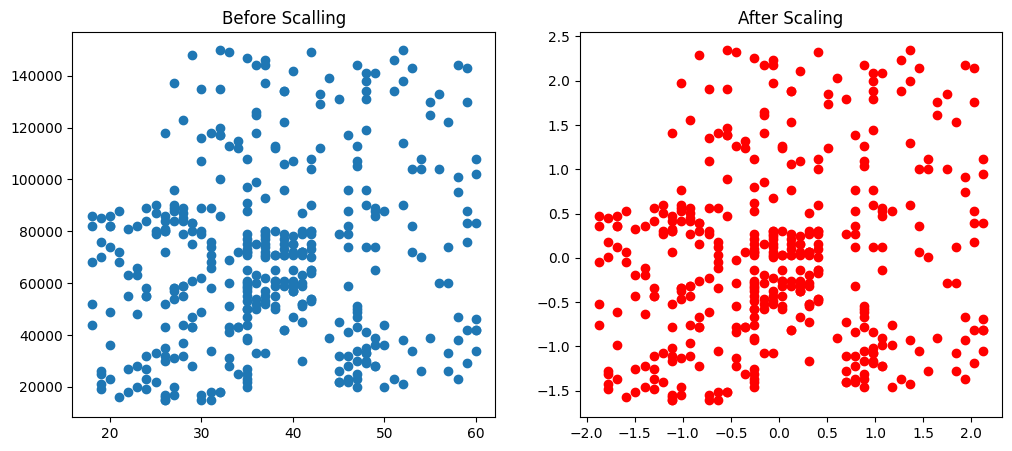

In [56]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title('Before Scalling')
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax2.set_title('After Scaling')
plt.show()

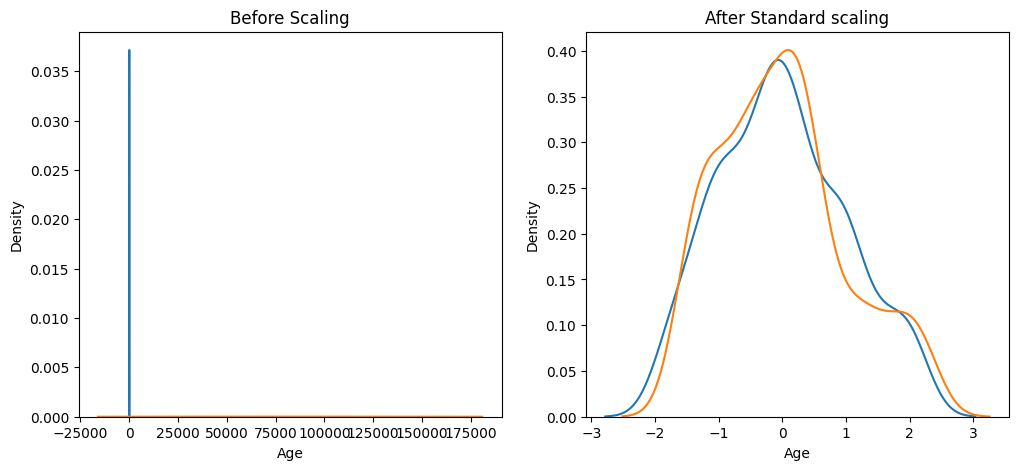

In [57]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before Scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)
sns.kdeplot(X_train['EstimatedSalary'], ax=ax1)

# After Scaling
ax2.set_title('After Standard scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax=ax2)
plt.show()

# Comparison of Distribution

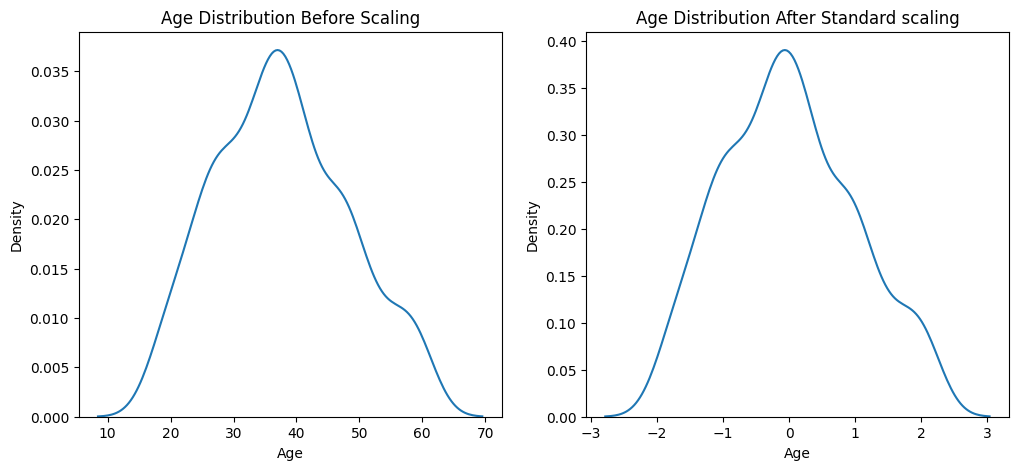

In [58]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before Scaling
ax1.set_title('Age Distribution Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)

# After Scaling
ax2.set_title('Age Distribution After Standard scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2)
plt.show()

why scaling is important

In [59]:
from sklearn.linear_model import LogisticRegression

In [60]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [61]:
lr.fit(X_train, Y_train)
lr_scaled.fit(X_train_scaled, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [62]:
y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [63]:
from sklearn.metrics import accuracy_score

In [64]:
print("Actual", accuracy_score(Y_test, y_pred))
print("Scaled", accuracy_score(Y_test, y_pred_scaled))

Actual 1.0
Scaled 1.0


In [65]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


# Effect of Outlier

In [70]:
new_rows = pd.DataFrame({
    'Age':[5,90,95],
    'EstimatedSalary':[1000,250000,350000],
    'Purchased':[0,1,1]
})

df = pd.concat([df, new_rows], ignore_index=True)

print(df)

     Age  EstimatedSalary  Purchased
0     19            19000          0
1     35            20000          0
2     26            43000          0
3     27            57000          0
4     19            76000          0
..   ...              ...        ...
398   36            33000          0
399   49            36000          1
400    5             1000          0
401   90           250000          1
402   95           350000          1

[403 rows x 3 columns]


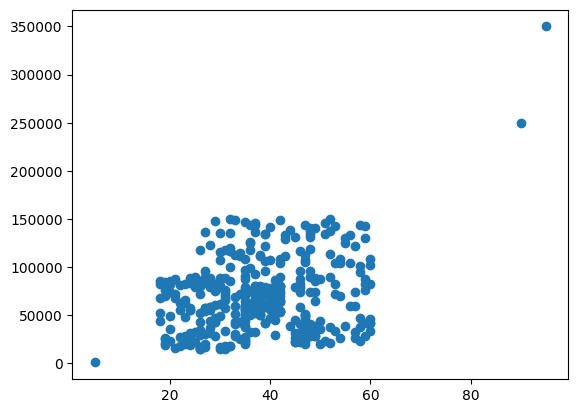

In [71]:
plt.scatter(df['Age'], df['EstimatedSalary'])

In [73]:
from sklearn.model_selection import train_test_split

scaler = StandardScaler()

# Fit the scaler to the train set, it will learn the parameters
scaler.fit(X_train)

# Transform Train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [75]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

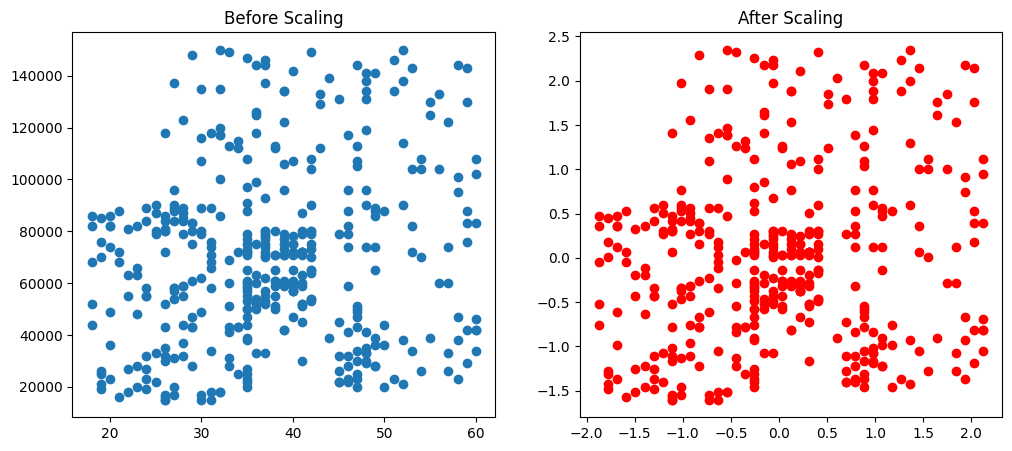

In [76]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Age'],X_train['EstimatedSalary'])
ax1.set_title('Before Scaling')
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'],color='red')
ax2.set_title('After Scaling')
plt.show()

# Normalization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\wine_data.csv', header=None, usecols=[0,1,2])
df.columns=['Class label', 'Alcohol', 'Malic acid']
print(df)

     Class label  Alcohol  Malic acid
0              1    14.23        1.71
1              1    13.20        1.78
2              1    13.16        2.36
3              1    14.37        1.95
4              1    13.24        2.59
..           ...      ...         ...
173            3    13.71        5.65
174            3    13.40        3.91
175            3    13.27        4.28
176            3    13.17        2.59
177            3    14.13        4.10

[178 rows x 3 columns]


<>:1: SyntaxWarning: invalid escape sequence '\B'
<>:1: SyntaxWarning: invalid escape sequence '\B'
C:\Users\Snehal\AppData\Local\Temp\ipykernel_19532\2613442385.py:1: SyntaxWarning: invalid escape sequence '\B'
  df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\wine_data.csv', header=None, usecols=[0,1,2])


<Axes: xlabel='Alcohol', ylabel='Density'>

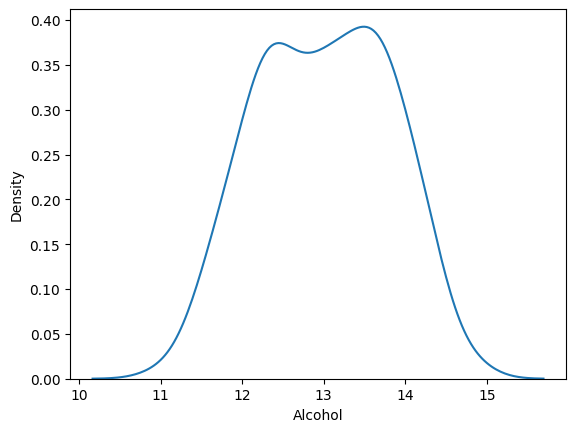

In [5]:
sns.kdeplot(df['Alcohol'])

<Axes: xlabel='Malic acid', ylabel='Density'>

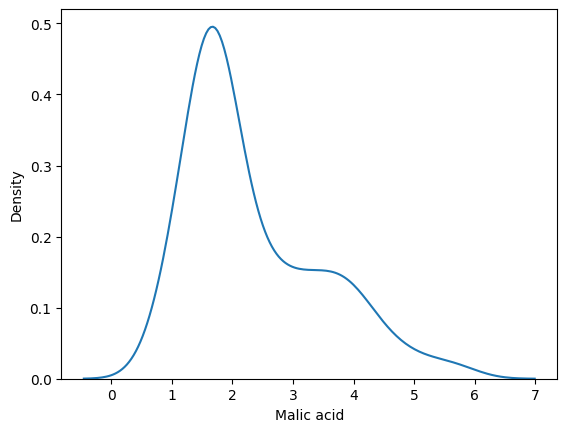

In [6]:
sns.kdeplot(df['Malic acid'])

<Axes: xlabel='Alcohol', ylabel='Malic acid'>

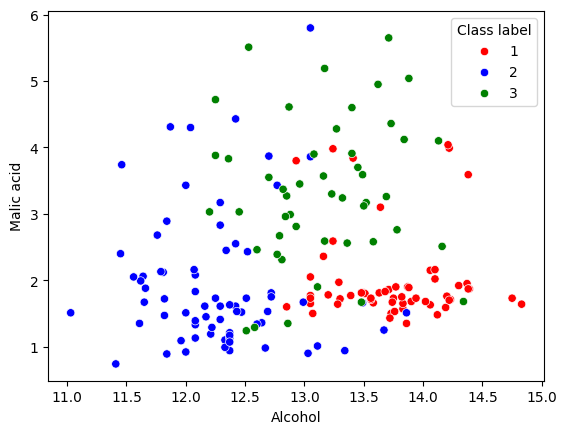

In [19]:
color_dict = {1:'red', 3:'Green', 2: 'blue'}
sns.scatterplot(
    data=df, 
    x='Alcohol', 
    y='Malic acid', 
    hue='Class label', 
    palette=color_dict
)

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(df.drop('Class label', axis = 1),
                                                    df['Class label'],
                                                    test_size=0.3,
                                                     random_state= 0 )
X_train.shape, X_test.shape

((124, 2), (54, 2))

In [24]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

# fit the scaler to the train set, it will learn the parameter
scaler.fit(X_train)

# transform train ands test sets

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test. columns)


In [29]:
np.round (X_train.describe(), 1)

,Alcohol,Malic acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

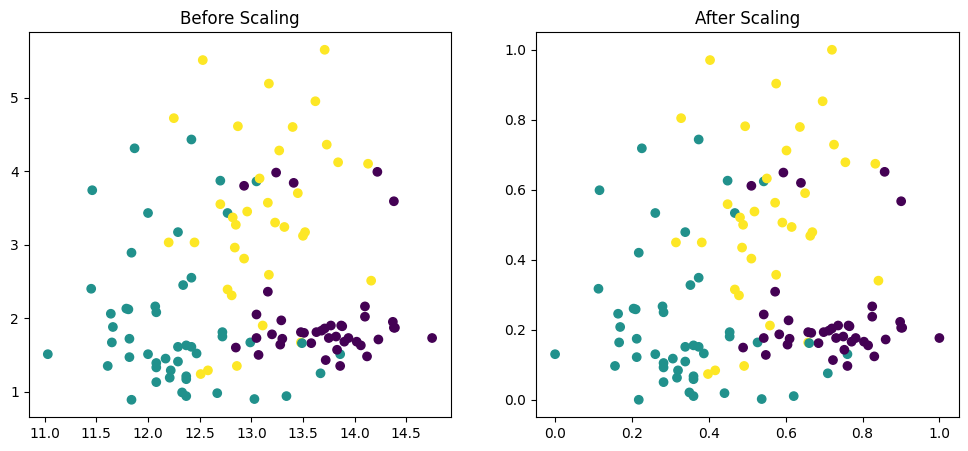

In [32]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

ax1.scatter(X_train['Alcohol'], X_train['Malic acid'], c = Y_train)
ax1.set_title('Before Scaling')
ax2.scatter(X_train_scaled['Alcohol'], X_train_scaled['Malic acid'], c=Y_train)
ax2.set_title('After Scaling')
plt.show()

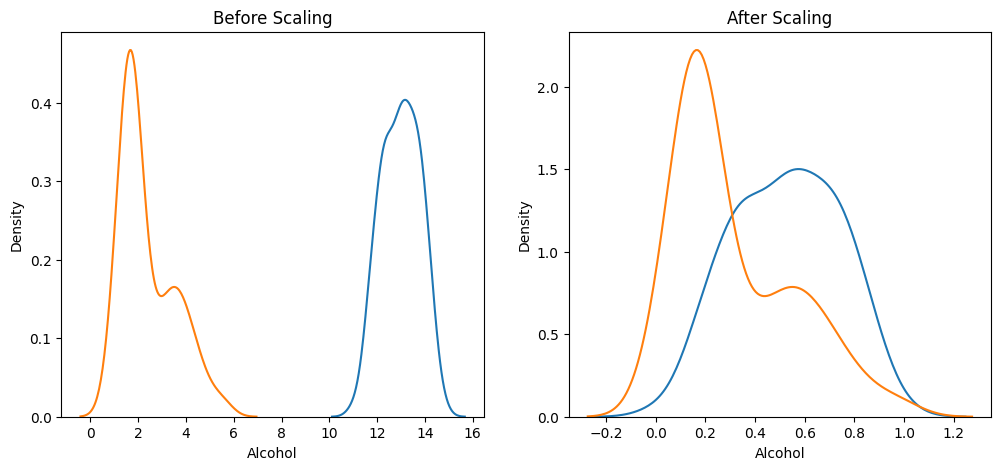

In [34]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

# Before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax=ax1)
sns.kdeplot(X_train['Malic acid'], ax=ax1)

# After Scaling
ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax=ax2)
sns.kdeplot(X_train_scaled['Malic acid'], ax=ax2)
plt.show()

<Axes: title={'center': 'Alcohol Distribution After Scaling'}, xlabel='Alcohol', ylabel='Density'>

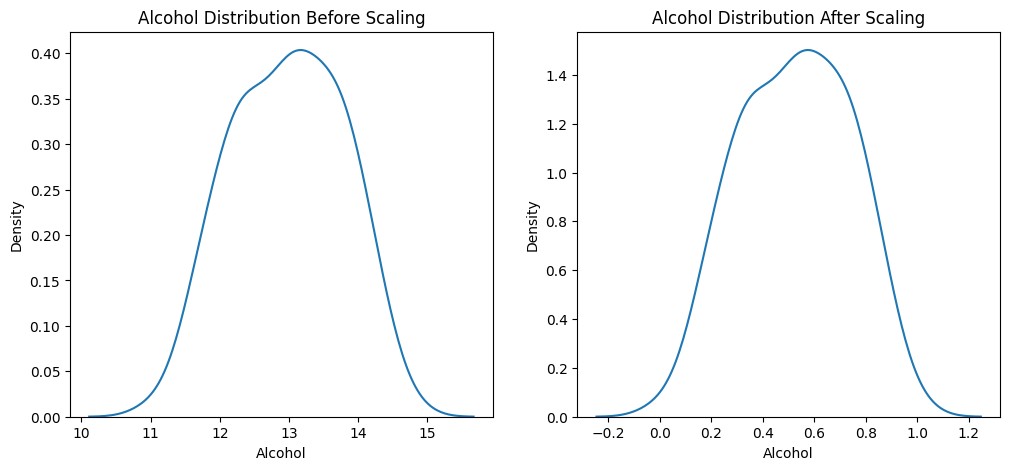

In [35]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

# Before scaling
ax1.set_title('Alcohol Distribution Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax=ax1)

# After Scaling
ax2.set_title('Alcohol Distribution After Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax=ax2)